# Methods and Pipeline

## Time Distortion Index (TDI)

Time distortion index (TDI) is a metric used to quantify differences between time series, and its formulation varies across applications (Frias-Paredes et al., 2016; Liu et al., 2023).

This notebook uses the TDI method developed in `tdi_plot.py` (`compute_tdi`) to test how the **shape** of the growth-rate and biomass time series differs between adjacent generations, for four media (basal, acetate, succinate, with amino acids) and 400+ gene knockouts (462 KOs in basal, 342-359 in the other media, 2 seeds each).

- **Principle:** for two adjacent generations of one run, the composite TDI is the average of three terms: the DTW distance (shape difference, normalised by series length and mean level), the duration ratio (|duration2 / duration1 - 1|) and the amplitude ratio (|max2 / max1 - 1|). Lower values mean the two generations are more alike.
- **Pipeline:** compute the TDI for every (medium, KO, seed) run and every adjacent generation pair, then average over runs for each medium. Slide an 8-generation window along the generations (first start at generation 3) and compute the mean growth-rate composite TDI of each window. The proposed window is the earliest one whose mean TDI is within 2% of the lowest value (lowest relative TDI, then lowest starting generation), since a lower start saves simulation time.


# Code


## Summary
(Time series of the four media, 462 KO x 2 seeds, loaded into `df_t` with a `medium` column)

In [1]:
# Load the four 462-KO time-series files (one per medium) into one dataframe with a `medium` column
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib
import tdi_plot
importlib.reload(tdi_plot)
compute_tdi = tdi_plot.compute_tdi

base = "/user/home/il22158/work/vEcoli/reading/results/growth_rate/"
files = {
    "acetate":   "growth_rate_timeseries_gene_knockout_462KO_acetate_all.parquet",
    "basal":     "growth_rate_timeseries_gene_knockout_462KO_basal_all.parquet",
    "succinate": "growth_rate_timeseries_gene_knockout_462KO_succinate_all.parquet",
    "aa":        "growth_rate_timeseries_gene_knockout_462KO_with_aa_all.parquet",
}
summary_files = {m: base + f.replace("timeseries", "summary").replace(".parquet", ".csv") for m, f in files.items()}
run_summary = pd.concat([pd.read_csv(f).assign(medium=m) for m, f in summary_files.items()], ignore_index=True)
df_t = pd.concat([pd.read_parquet(base + f).assign(medium=m) for m, f in files.items()], ignore_index=True)

save_dir = "/user/home/il22158/work/vEcoli/reading/results/tdi"
os.makedirs(save_dir, exist_ok=True)

print("shape:", df_t.shape)
print(df_t.groupby("medium").agg(rows=("time", "size"), KOs=("label", "nunique"),
                                 seeds=("lineage_seed", "nunique"), max_generation=("generation", "max")))
print(run_summary.groupby("medium").agg(runs=("label", "size"), max_generation=("max_generation", "max"),
                                         median_duration_sec=("duration_sec", "median")))


shape: (1595033, 9)
             rows  KOs  seeds  max_generation
medium                                       
aa         261974  349      2              20
acetate    426040  359      2              20
basal      425475  462      2              12
succinate  481544  342      2              20
           runs  max_generation  median_duration_sec
medium                                              
aa          697              20               2640.0
acetate     715              20              13707.0
basal       924              12              35558.0
succinate   682              20              58881.5


In [2]:
# TDI between adjacent generations, for each (medium, KO, seed) run
feature_map = {
    "Growth rate": "listeners__mass__instantaneous_growth_rate",
    "Biomass": "listeners__mass__dry_mass",
}
media = ["basal", "acetate", "succinate", "aa"]

records = []
for (medium, ko, seed), run in df_t.groupby(["medium", "label", "lineage_seed"]):
    by_gen = {g: x.sort_values("time") for g, x in run.groupby("generation")}
    for g in sorted(by_gen):
        if g + 1 not in by_gen:
            continue
        prev_df, curr_df = by_gen[g], by_gen[g + 1]
        if len(prev_df) < 2 or len(curr_df) < 2:
            continue
        for feature, col in feature_map.items():
            with np.errstate(all="ignore"):
                m = compute_tdi(prev_df, curr_df, col)
            if all(np.isfinite(v) for v in m.values()):
                records.append({"medium": medium, "label": ko, "seed": seed, "feature": feature,
                                "generation_start": g, **m})

results = pd.DataFrame(records)
metrics = ["composite_tdi", "dtw_distance", "duration_ratio", "amplitude_ratio"]
summary = (results.groupby(["medium", "feature", "generation_start"])
                  .agg(**{f"{k}_{s}": (k, s) for k in metrics for s in ("mean", "std")}, count=("composite_tdi", "size"))
                  .reset_index().fillna(0.0))
summary.to_csv(os.path.join(save_dir, "tdi_all_variants_462KO_4media_4metrics_mean_std.csv"), index=False)
print(summary.groupby(["medium", "feature"])["count"].agg(["min", "max"]))


                       min  max
medium    feature              
aa        Biomass      182  298
          Growth rate  182  298
acetate   Biomass      274  366
          Growth rate  274  366
basal     Biomass      606  772
          Growth rate  606  772
succinate Biomass      328  503
          Growth rate  328  503


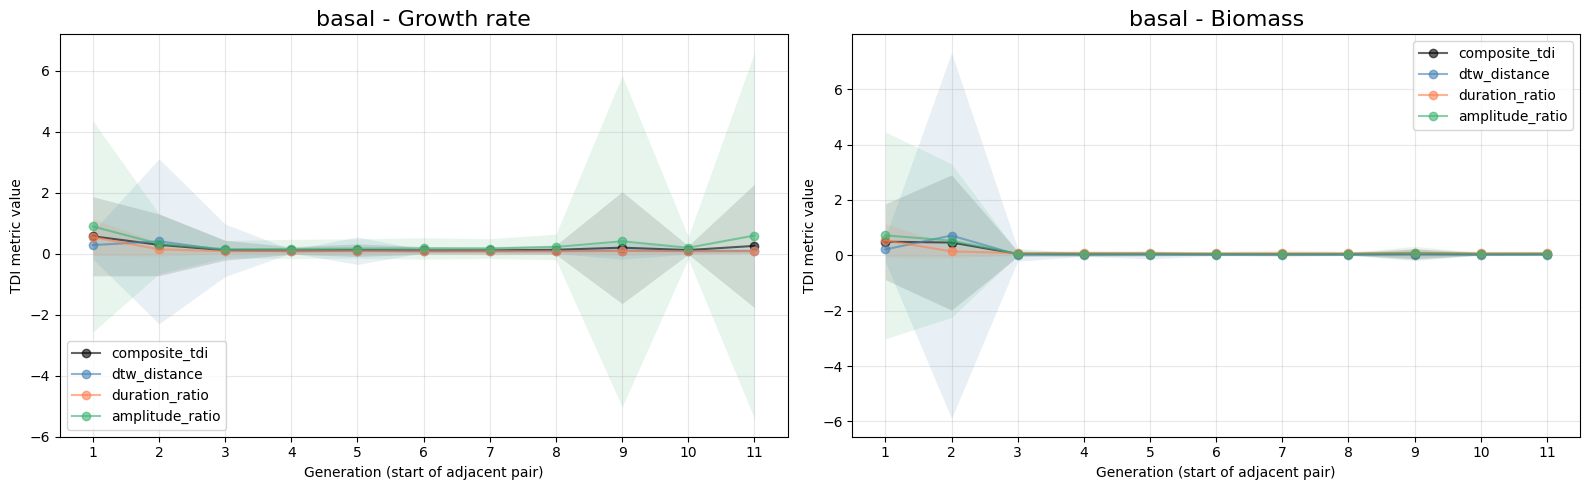

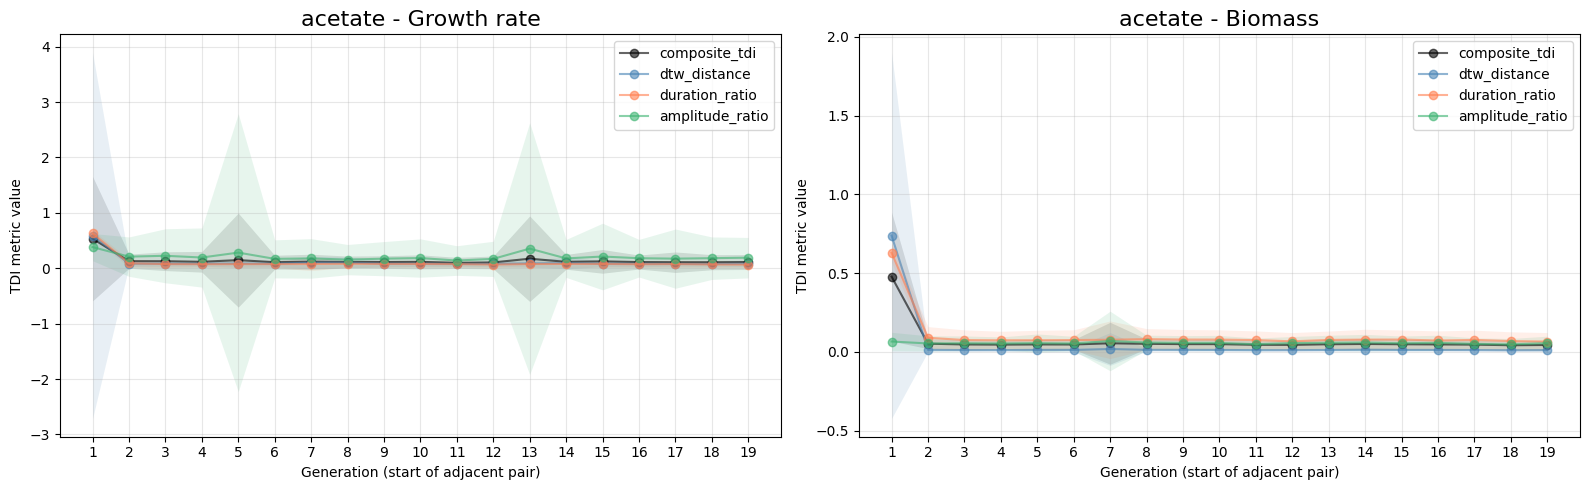

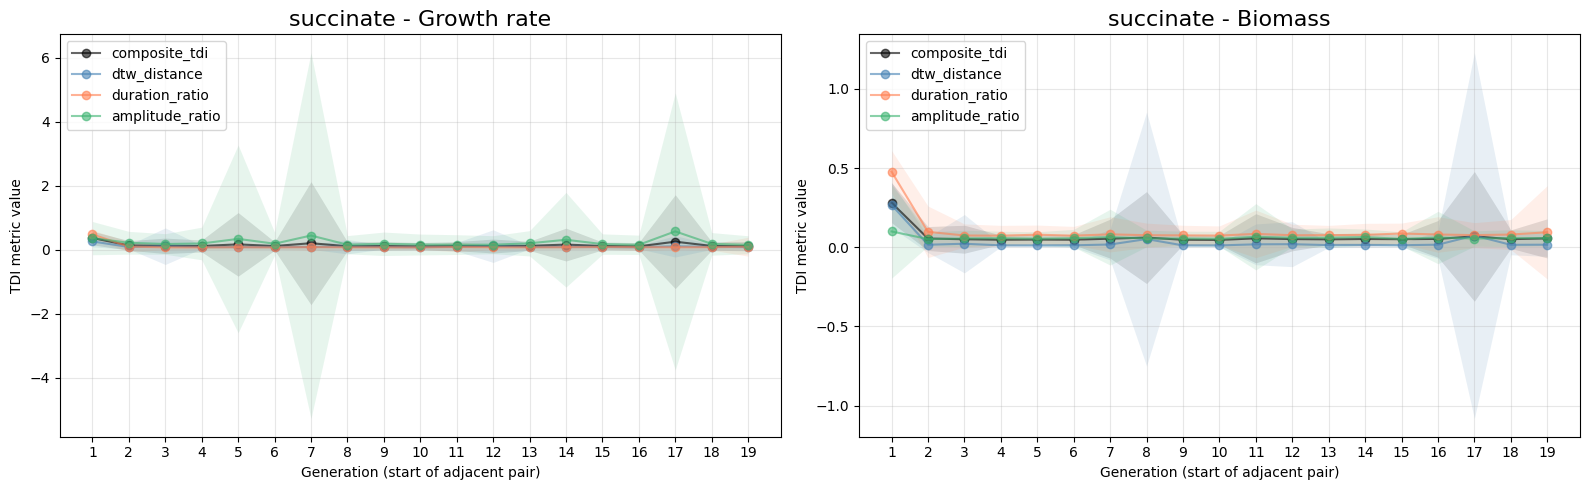

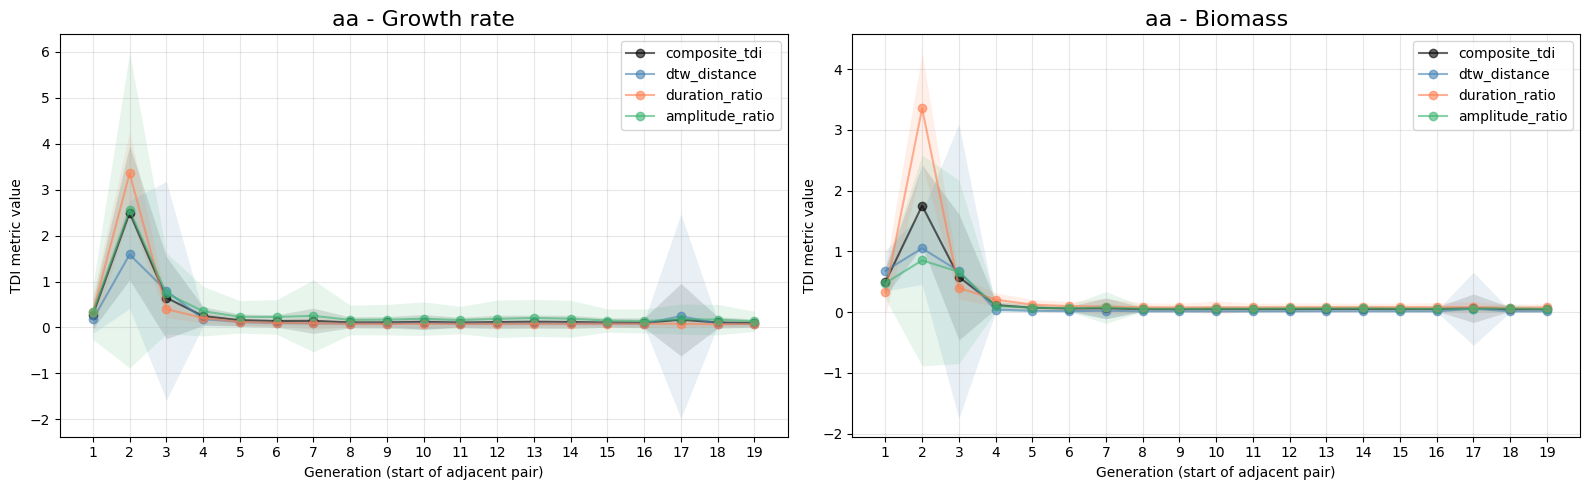

In [3]:
# Mean +/- std of the four TDI metrics per medium (left: growth rate, right: biomass)
colors = {"composite_tdi": "black", "dtw_distance": "steelblue",
          "duration_ratio": "coral", "amplitude_ratio": "mediumseagreen"}
for medium in media:
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    for ax, feature in zip(axes, feature_map):
        s = summary[(summary["medium"] == medium) & (summary["feature"] == feature)]
        for k, c in colors.items():
            ax.plot(s["generation_start"], s[f"{k}_mean"], marker="o", color=c, alpha=0.6, label=k)
            ax.fill_between(s["generation_start"], s[f"{k}_mean"] - s[f"{k}_std"],
                            s[f"{k}_mean"] + s[f"{k}_std"], color=c, alpha=0.12, linewidth=0)
        ax.set_title(f"{medium} - {feature}", fontsize=16)
        ax.set_xticks(s["generation_start"].astype(int))
        ax.set_xlabel("Generation (start of adjacent pair)"); ax.set_ylabel("TDI metric value")
        ax.grid(True, alpha=0.3); ax.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, f"tdi_462KO_{medium}_4metrics_mean_std.png"), dpi=200, bbox_inches="tight")
    plt.show()


# Results and Conclusion

## Data sources
- Time series (one file per medium, concatenated with a `medium` column): `/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_timeseries_gene_knockout_462KO_{acetate,basal,succinate,with_aa}_all.parquet`
- Run summaries: `/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_summary_gene_knockout_462KO_{acetate,basal,succinate,with_aa}_all.csv`
- Per-generation TDI table: [tdi_all_variants_462KO_4media_4metrics_mean_std.csv](/user/home/il22158/work/vEcoli/reading/results/tdi/tdi_all_variants_462KO_4media_4metrics_mean_std.csv)
- Proposed windows: [tdi_summary_462KO_4media_composite_tdi.csv](/user/home/il22158/work/vEcoli/reading/results/tdi/tdi_summary_462KO_4media_composite_tdi.csv)

## Basal Media
![Basal TDI](results/tdi/tdi_462KO_basal_4metrics_mean_std.png)

## AA Media
![AA TDI](results/tdi/tdi_462KO_aa_4metrics_mean_std.png)

## Succinate Media
![Succinate TDI](results/tdi/tdi_462KO_succinate_4metrics_mean_std.png)

## Acetate Media
![Acetate TDI](results/tdi/tdi_462KO_acetate_4metrics_mean_std.png)


In [4]:
# Proposed generation window per medium: slide an 8-generation window from generation 3 and compute its mean
# growth-rate composite TDI. Optimum = the earliest window whose mean TDI is within TOL (relative) of the lowest one.
FIRST_START, LENGTH, TOL = 3, 8, 0.1
media_names = {"basal": "basal", "aa": "with_aa", "succinate": "succinate", "acetate": "acetate"}  # names used by the downstream notebook

rows, scan = [], []
for medium, name in media_names.items():
    gr = (summary[(summary["medium"] == medium) & (summary["feature"] == "Growth rate")]
          .set_index("generation_start")["composite_tdi_mean"])
    bio = (summary[(summary["medium"] == medium) & (summary["feature"] == "Biomass")]
           .set_index("generation_start")["composite_tdi_mean"])
    starts = [s for s in gr.index if s >= FIRST_START and all(g in gr.index for g in range(s, s + LENGTH))]
    scan += [{"medium": medium, "start": s, "mean_tdi": gr.loc[s:s + LENGTH - 1].mean()} for s in starts]
    lowest = min(sc["mean_tdi"] for sc in scan if sc["medium"] == medium)
    best = min(sc["start"] for sc in scan if sc["medium"] == medium and sc["mean_tdi"] <= lowest * (1 + TOL))
    end = best + LENGTH - 1
    runs = run_summary[run_summary["medium"] == medium]
    rows.append({
        "Media": name,
        "Proposed generation window": f"{best}-{end}",
        "Biomass mean composite TDI": bio.loc[best:end].mean(),
        "Growth-rate mean composite TDI": gr.loc[best:end].mean(),
        "Runs reaching window end": f"{(runs['max_generation'] >= end + 1).sum()} / {len(runs)}",
    })

window_summary = pd.DataFrame(rows)
display(window_summary)
window_summary.to_csv(os.path.join(save_dir, "tdi_summary_462KO_4media_composite_tdi.csv"), index=False)


,Media,Proposed generation window,Biomass mean composite TDI,Growth-rate mean composite TDI,Runs reaching window end
0,basal,3-10,0.050055,0.123123,607 / 924
1,with_aa,6-13,0.052705,0.122379,199 / 697
2,succinate,4-11,0.051340,0.131036,389 / 682
3,acetate,3-10,0.049048,0.120043,326 / 715


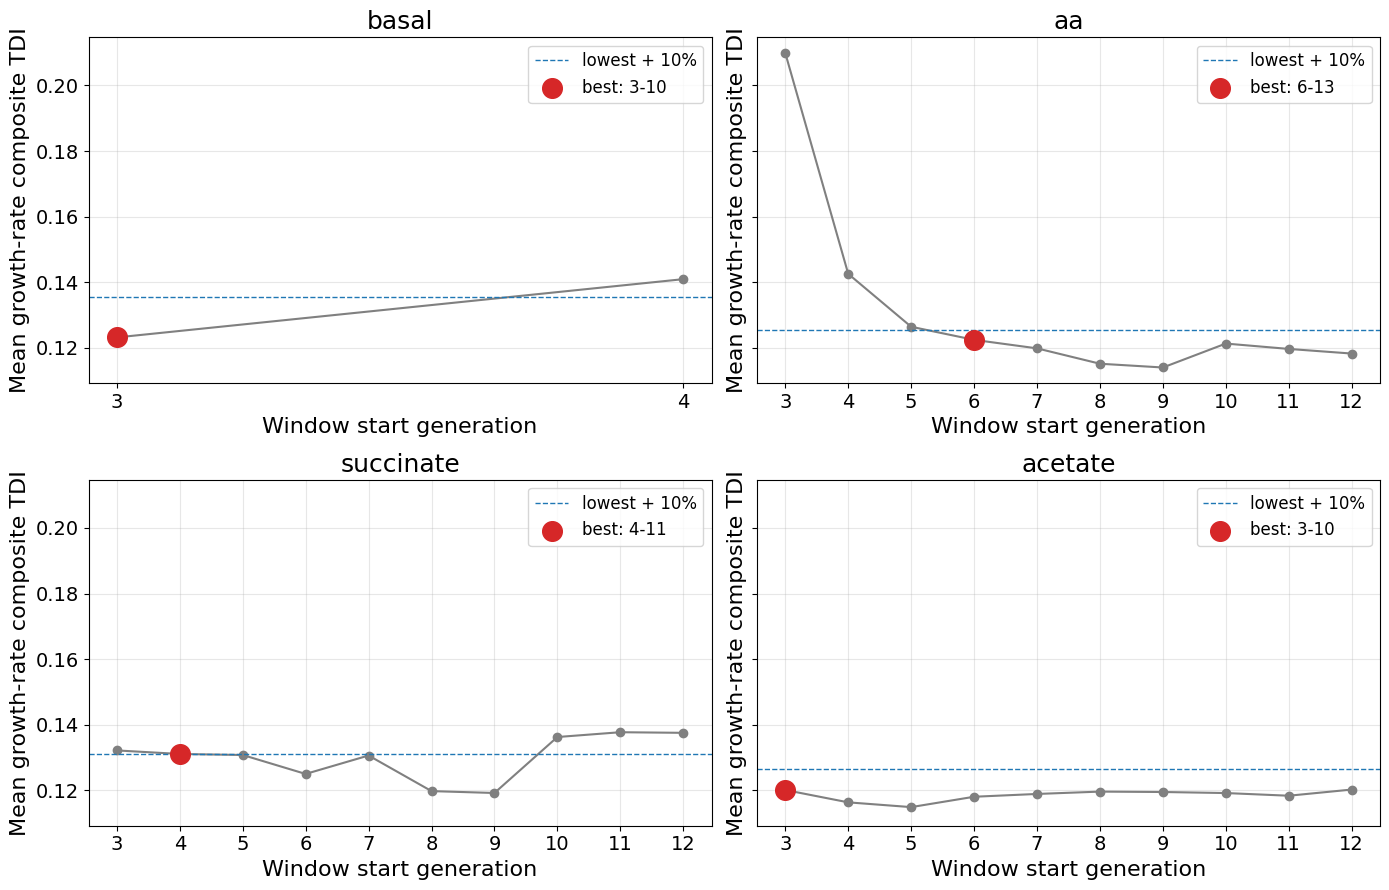

In [5]:
# Sliding-window scan and chosen window: mean growth-rate composite TDI of every candidate 8-generation window
scan = pd.DataFrame(scan)
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)
for ax, (medium, name) in zip(axes.flat, media_names.items()):
    sc = scan[scan["medium"] == medium]
    ax.plot(sc["start"], sc["mean_tdi"], marker="o", color="grey")
    ax.axhline(sc["mean_tdi"].min() * (1 + TOL), color="C0", ls="--", lw=1, label=f"lowest + {TOL:.0%}")
    b = sc[sc["start"] == min(sc.loc[sc["mean_tdi"] <= sc["mean_tdi"].min() * (1 + TOL), "start"])].iloc[0]
    ax.scatter([b["start"]], [b["mean_tdi"]], s=200, color="C3", zorder=3, label=f"best: {int(b['start'])}-{int(b['start']) + LENGTH - 1}")
    ax.set_xticks(sc["start"])
    ax.set_title(medium, fontsize=18)
    ax.set_xlabel("Window start generation", fontsize=16); ax.set_ylabel("Mean growth-rate composite TDI", fontsize=16)
    ax.tick_params(labelsize=14); ax.legend(fontsize=12); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(save_dir, "tdi_462KO_window_selection.png"), dpi=200, bbox_inches="tight")
plt.show()


## Results and Discussion
